In [6]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, pearsonr
from functools import reduce
from datetime import datetime

import sys
from pathlib import Path

def find_repo_root(marker='core') -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / marker).is_dir():
            return candidate
    raise RuntimeError(f"Could not locate repo root (no '{marker}/' found above {Path.cwd()})")
sys.path.insert(0, str(find_repo_root() / 'core'))
from participants import get_participants

# FREQ_FILE = sorted(Path(FREQ_PATH).glob('*CastellarBand-alpha_statsnorm.csv'))[-1].name
# RT_FILE   = sorted(Path(RT_PATH).glob('*active_oddball_rt_flow*.csv'))[-1].name  # or CSV

# ==============================================================================
# CONFIGURATION
# ==============================================================================

FREQ_FILE   = "20261016_active_36p_flow_CastellarBand-alpha_statsnorm.csv"
RT_FILE     = "20261016_active_oddball_rt_flow.CSV"

BAND_METHOD = 'castellar_exact'  # or 'castellar_trial'
ELECTRODES  = ["Fz", "FCz", "Cz"]
METHOD_CORR = "pearson"           # correlation method used throughout: "pearson" | "spearman"
date        = datetime.today().strftime("%Y_%m_%d")

# Participant inclusion — sourced from the shared function, not a hardcoded list
INCLUDED_UIDS = list(get_participants("flow", "active").keys())
print(f"Included participants ({len(INCLUDED_UIDS)}): {INCLUDED_UIDS}")

if sys.platform == "win32":
    FREQ_PATH = Path(r'L:/EEG_Flow_data/Study_EEG_Flow_Active/derivatives_v2/outputs/measures/flow/freq/castellar')
    RT_PATH = Path(r'L:/EEG_Flow_data/Study_EEG_Flow_Active/derivatives_v2/outputs/measures/behavior')
    root_img  = Path("L:/EEG_Flow_data/Study_EEG_Flow_Active/derivatives_v2/outputs/img/flow/AlphaRT_correlation")
else:
    FREQ_PATH = Path("/Volumes/faculty/EEG_Flow_data/Study_EEG_Flow_Active/derivatives_v2/output/measures/freq/cropped_Castellar")
    RT_PATH = Path(f"L:/EEG_Flow_data/Study_EEG_Flow_Active/derivatives_v2/outputs/measures/behavior")
    root_img  = Path("/Volumes/faculty/EEG_Flow_data/Study_EEG_Flow_Active/derivatives_v2/output/img/flow/AlphaRT_correlation")

root_img.mkdir(parents=True, exist_ok=True)

Included participants (36): ['P02', 'P04', 'P05', 'P07', 'P08', 'P10', 'P12', 'P13', 'P14', 'P15', 'P16', 'P18', 'P22', 'P23', 'P26', 'P27', 'P30', 'P31', 'P32', 'P33', 'P53', 'P55', 'P58', 'P59', 'P60', 'P61', 'P62', 'P63', 'P65', 'P66', 'P67', 'P69', 'P72', 'P73', 'P74', 'P75']


In [7]:
# ==============================================================================
# LOAD ALPHA POWER — filtered to method + electrodes of interest
# ==============================================================================
df_freq = pd.read_csv(f"{FREQ_PATH}/{FREQ_FILE}")
df_freq = df_freq[df_freq['cond'].isin(['UT_highflow', 'UT_lowflow'])]

print(f"Available methods: {df_freq['method'].unique().tolist()}")
print(f"Using method: {BAND_METHOD}")

df_subset = df_freq[
    (df_freq["electrode"].isin(ELECTRODES)) &
    (df_freq["method"] == BAND_METHOD)
]

df_avg_freq = (
    df_subset
    .groupby(["participant", "cond"], as_index=False)
    .agg({"power": "mean"})
    .rename(columns={"cond": "condition", "power": "alpha_power"})
)

# Difference version (High - Low), wide format
alpha_wide = (
    df_avg_freq
    .pivot(index="participant", columns="condition", values="alpha_power")
    .reset_index()
)
alpha_wide['ALPHAdiff'] = alpha_wide['UT_highflow'] - alpha_wide['UT_lowflow']
alpha_wide = alpha_wide[["participant", "ALPHAdiff"]]
alpha_wide.columns.name = None


Available methods: ['castellar_exact', 'castellar_trial']
Using method: castellar_exact


In [9]:
# ==============================================================================
# LOAD REACTION TIME
# ==============================================================================
df_RT = pd.read_csv(f"{RT_PATH}/{RT_FILE}").rename(columns={"Participant": "participant", "Condition": "condition", "rt_mean": "response_time"})

# Normalize condition naming to match df_avg_freq's convention
# (df_RT uses "High Flow"/"Low Flow"/"AudioOnly1"/"AudioOnly2";
#  df_avg_freq uses "high_flow"/"low_flow"/"oddball_1"/"oddball_2")
CONDITION_MAP = {
    'High Flow': 'UT_highflow',
    'Low Flow':  'UT_lowflow',
    # AudioOnly1/2 intentionally left unmapped — not part of the flow contrast,
    # will be dropped below
}
df_RT["condition"] = df_RT["condition"].replace(CONDITION_MAP)
df_RT = df_RT[df_RT['condition'].isin(['UT_highflow', 'UT_lowflow'])]

RT_wide = (
    df_RT
    .pivot(index="participant", columns="condition", values="response_time")
    .reset_index()
)
RT_wide['RTdiff'] = RT_wide['UT_highflow'] - RT_wide['UT_lowflow']
RT_wide = RT_wide[["participant", "RTdiff"]]
RT_wide.columns.name = None

In [10]:
# ==============================================================================
# MERGE — raw (per condition) and difference versions
# ==============================================================================
df_merged = reduce(
    lambda left, right: pd.merge(left, right, on=["participant", "condition"], how="left"),
    [df_avg_freq, df_RT]
)
df_merged = df_merged[df_merged['condition'].isin(['UT_highflow', 'UT_lowflow'])]

df_diff_merged = reduce(
    lambda left, right: pd.merge(left, right, on="participant", how="left"),
    [alpha_wide, RT_wide]
)

# Apply participant inclusion — same list/logic as previous version
df_merged = df_merged[df_merged["participant"].isin(INCLUDED_UIDS)]
n_part = df_merged["participant"].nunique()
print(f"N participants (raw, after inclusion filter): {n_part}")

df_diff_merged = df_diff_merged[df_diff_merged["participant"].isin(INCLUDED_UIDS)]
n_part_diff = df_diff_merged["participant"].nunique()
print(f"N participants (difference, after inclusion filter): {n_part_diff}")

N participants (raw, after inclusion filter): 36
N participants (difference, after inclusion filter): 36


In [11]:
# ==============================================================================
# PLOTTING FUNCTIONS
# ==============================================================================
def plot_raw_correlations_per_condition(
    df, erp_cols, behav_cols, condition_col,
    method="spearman", figsize=None, col_width=4.5, row_height=3.5,
    palette="Set1", title=None, save_tag=""
):
    n_rows, n_cols = len(erp_cols), len(behav_cols)
    if figsize is None:
        figsize = (max(6, n_cols * col_width), max(4, n_rows * row_height))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=figsize, sharex="col", sharey="row")
    axes = np.atleast_2d(axes)

    conditions = df[condition_col].unique()
    n_part = df["participant"].nunique()

    for i, erp_var in enumerate(erp_cols):
        for j, behav_var in enumerate(behav_cols):
            ax = axes[i, j]

            for cond_idx, cond in enumerate(conditions):
                plot_df = df[df[condition_col] == cond][[erp_var, behav_var]].dropna()

                sns.scatterplot(
                    data=plot_df, x=behav_var, y=erp_var,
                    s=50, alpha=0.9, edgecolor="k", label=cond, ax=ax, palette=palette
                )
                sns.regplot(
                    data=plot_df, x=behav_var, y=erp_var,
                    scatter=False, ax=ax, line_kws=dict(alpha=0.8)
                )

                if len(plot_df) >= 3:
                    corr_fn = spearmanr if method.lower() == "spearman" else pearsonr
                    rho, p = corr_fn(plot_df[behav_var], plot_df[erp_var])
                    txt = f"{cond}: {method.capitalize()} \u03c1={rho:.2f}, p={p:.3g}"
                else:
                    txt = f"{cond}: n/a"
                ax.text(0.05, 0.95 - 0.05 * cond_idx, txt, transform=ax.transAxes, va="top", fontsize=10)

            # Connect same-participant points across conditions
            for participant_id, df_sub in df.groupby("participant"):
                df_sub = df_sub[[condition_col, behav_var, erp_var]].dropna()
                df_sub = df_sub[df_sub[condition_col].isin(conditions)]
                if len(df_sub) > 1:
                    ax.plot(df_sub[behav_var], df_sub[erp_var], color="gray", alpha=0.4, linewidth=1)

            ax.grid(True, alpha=0.25)
            ax.set_xlabel(behav_var if i == n_rows - 1 else "")
            ax.set_ylabel(erp_var if j == 0 else "")

    plt.tight_layout(rect=[0, 0, 0.98, 0.95])
    if title:
        fig.suptitle(f"{title}, N={n_part}", fontsize=12)
    fig.savefig(f"{root_img}/alphaRT_correlation_raw_{n_part}p_{save_tag}_{date}.png",
                dpi=300, bbox_inches="tight")
    plt.legend(title=condition_col, bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.show()


def plot_difference_correlation(
    df, erp_cols, behav_cols, method="spearman",
    figsize=None, col_width=4.5, row_height=3.5, title=None, save_tag=""
):
    n_rows, n_cols = len(erp_cols), len(behav_cols)
    if figsize is None:
        figsize = (max(6, n_cols * col_width), max(4, n_rows * row_height))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=figsize, sharex="col", sharey="row")
    axes = np.atleast_2d(axes)

    n_part = df["participant"].nunique() if "participant" in df.columns else len(df)

    for i, erp_var in enumerate(erp_cols):
        for j, behav_var in enumerate(behav_cols):
            ax = axes[i, j]
            plot_df = df[[erp_var, behav_var]].dropna()

            sns.scatterplot(data=plot_df, x=behav_var, y=erp_var, s=50, alpha=0.9, edgecolor="k", ax=ax)
            sns.regplot(data=plot_df, x=behav_var, y=erp_var, scatter=False, ax=ax,
                        line_kws=dict(color="black", linewidth=2, alpha=0.8))

            if len(plot_df) >= 3:
                corr_fn = spearmanr if method.lower() == "spearman" else pearsonr
                rho, p = corr_fn(plot_df[behav_var], plot_df[erp_var])
                txt = f"\u03c1={rho:.2f}, p={p:.3g}"
            else:
                txt = "n/a"
            ax.text(0.05, 0.95, txt, transform=ax.transAxes, va="top", fontsize=12)

            ax.axhline(0, color="black", linestyle="--", linewidth=0.8, alpha=0.7)
            ax.axvline(0, color="black", linestyle="--", linewidth=0.8, alpha=0.7)
            ax.grid(True, alpha=0.25)
            ax.set_xlabel(behav_var if i == n_rows - 1 else "")
            ax.set_ylabel(erp_var if j == 0 else "")

    plt.tight_layout(rect=[0, 0, 0.98, 0.95])
    if title:
        fig.suptitle(f"{title}, N={n_part}", fontsize=12)
    fig.savefig(f"{root_img}/alphaRT_correlation_diff_{n_part}p_{save_tag}_{date}.png",
                dpi=300, bbox_inches="tight")
    plt.show()

C:\Users\anguyen\AppData\Local\Temp\ipykernel_30656\2920132999.py:25: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(
C:\Users\anguyen\AppData\Local\Temp\ipykernel_30656\2920132999.py:25: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(


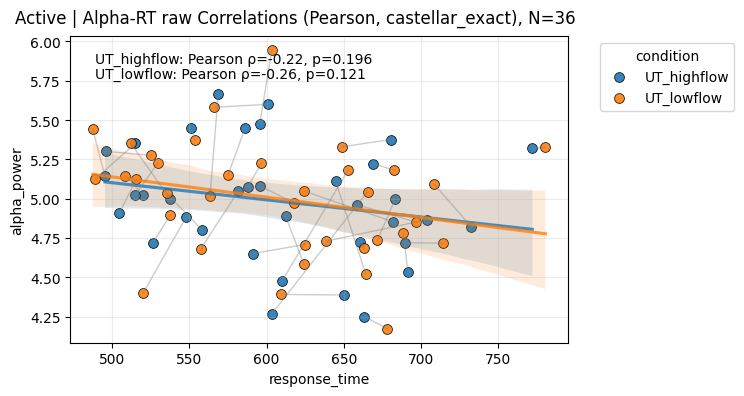

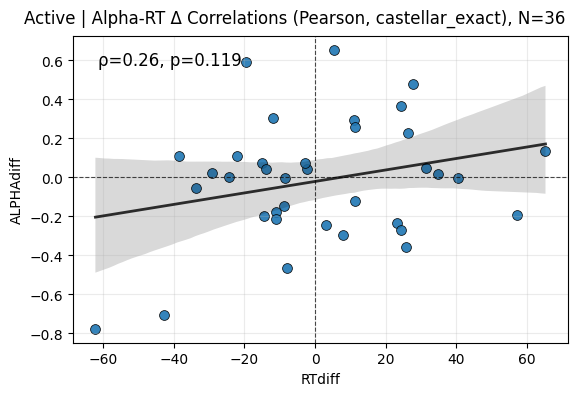

In [12]:
# ==============================================================================
# RUN
# ==============================================================================
plot_raw_correlations_per_condition(
    df=df_merged,
    erp_cols=["alpha_power"],
    behav_cols=["response_time"],
    condition_col="condition",
    method=METHOD_CORR,
    title=f"Active | Alpha-RT raw Correlations ({METHOD_CORR.capitalize()}, {BAND_METHOD})",
    save_tag=f"{METHOD_CORR}_{BAND_METHOD}",
)

plot_difference_correlation(
    df=df_diff_merged,
    erp_cols=["ALPHAdiff"],
    behav_cols=["RTdiff"],
    method=METHOD_CORR,
    title=f"Active | Alpha-RT \u0394 Correlations ({METHOD_CORR.capitalize()}, {BAND_METHOD})",
    save_tag=f"{METHOD_CORR}_{BAND_METHOD}",
)